In [2]:
import pandas as pd

results = pd.read_csv("data/results.csv")
goals = pd.read_csv("data/goalscorers.csv")
shootouts = pd.read_csv("data/shootouts.csv")
former = pd.read_csv("data/former_names.csv")

In [3]:
print(f"results: {results.shape} | goals: {goals.shape}")

results: (49945, 9) | goals: (47914, 8)


In [4]:
print("\n--- RESULTS ---")
print(results.head(2))
print(results.dtypes)


--- RESULTS ---
         date home_team away_team  home_score  away_score tournament     city  \
0  1872-11-30  Scotland   England           0           0   Friendly  Glasgow   
1  1873-03-08   England  Scotland           4           2   Friendly   London   

    country  neutral  
0  Scotland    False  
1   England    False  
date          object
home_team     object
away_team     object
home_score     int64
away_score     int64
tournament    object
city          object
country       object
neutral         bool
dtype: object


In [5]:
print("\n--- GOALSCORERS ---")
print(goals.head(2))
print(goals['minute'].unique()[:20]) 
print(goals['own_goal'].value_counts(dropna=False))
print(goals['penalty'].value_counts(dropna=False))
print(goals['scorer'].isna().sum(), "gols sem nome do artilheiro")


--- GOALSCORERS ---
         date home_team away_team     team            scorer  minute  \
0  1916-07-02     Chile   Uruguay  Uruguay   José Piendibene    44.0   
1  1916-07-02     Chile   Uruguay  Uruguay  Isabelino Gradín    55.0   

   own_goal  penalty  
0     False    False  
1     False    False  
[44. 55. 70. 75.  2. 60. 62. 67. 81. 29. 85. 10. 23.  8. 58. 77. 20. 15.
 39. 56.]
own_goal
False    46978
True       936
Name: count, dtype: int64
penalty
False    44648
True      3266
Name: count, dtype: int64
44 gols sem nome do artilheiro


In [6]:
print("\n--- FORMER NAMES ---")
print(former.head(10))


--- FORMER NAMES ---
          current                                former  start_date  \
0           Benin                               Dahomey  1959-11-08   
1    Burkina Faso                           Upper Volta  1960-04-14   
2         Curaçao                  Netherlands Antilles  1957-03-03   
3  Czechoslovakia                               Bohemia  1903-04-05   
4  Czechoslovakia                   Bohemia and Moravia  1939-01-01   
5  Czechoslovakia  Representation of Czechs and Slovaks  1993-03-24   
6        DR Congo                         Belgian Congo  1948-05-25   
7        DR Congo                    Congo-Léopoldville  1963-04-12   
8        DR Congo                        Congo-Kinshasa  1965-01-09   
9        DR Congo                                 Zaïre  1971-01-10   

     end_date  
0  1975-11-30  
1  1984-08-04  
2  2010-10-10  
3  1919-01-01  
4  1945-05-01  
5  1993-11-17  
6  1956-01-02  
7  1964-07-19  
8  1970-11-24  
9  1997-04-27  


In [7]:
goals.shape

(47914, 8)

In [8]:
for df in [results, goals]:
    df['date'] = pd.to_datetime(df['date'], errors='coerce')
    df['year'] = df['date'].dt.year

In [10]:
results.head()

,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral,year
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False,1872
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False,1873
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False,1874
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False,1875
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False,1876


In [9]:
# cria um dicionario que troca os nomes antigos dos paises pelos novos.
name_map = dict(zip(former['former'], former['current']))

In [11]:
# utiliza o dicionario da celula acima, e troca o nome dos paises que trocaram o nome mais de uma vez.
def unify_names(series):
    # repete até não mudar mais
    s = series.replace(name_map)
    # 2ª passada pra pegar casos tipo Belgian Congo -> Zaire -> DR Congo
    s = s.replace(name_map)
    return s

In [12]:
for col in ['home_team', 'away_team']:
    results[col] = unify_names(results[col])

In [13]:
for col in ['home_team', 'away_team', 'team']:
    goals[col] = unify_names(goals[col])

In [14]:
print(f"Minutos nulos: {goals['minute'].isna().sum()}") # contabilizar os gols sem minuto


Minutos nulos: 254


In [15]:
goals['minute'] = goals['minute'].astype('float') # apenas para garantir que o tipo dos dados dessa coluna sejam Float

In [16]:
# salva a versão limpa dos dados para não ter que fazer novamente
results.to_csv("data/results_clean.csv", index=False)
goals.to_csv("data/goals_clean.csv", index=False)

In [17]:
print(f"Times únicos antes: ~230 | Depois: {results['home_team'].nunique()}") 

Times únicos antes: ~230 | Depois: 328


In [18]:
print(f"Brasil aparece como: {results[results['home_team'].str.contains('Brazil', na=False)]['home_team'].unique()}")

Brasil aparece como: ['Brazil']


In [19]:
import plotly.express as px

In [20]:
results = pd.read_csv("data/results_clean.csv", parse_dates=['date'])
goals = pd.read_csv("data/goals_clean.csv", parse_dates=['date'])

In [23]:
merged = goals.merge(
    results[['date','home_team','away_team','tournament']], 
    on=['date','home_team','away_team'], 
    how='left'
)

In [24]:
goals_validos = merged[(merged['scorer'].notna()) & (merged['own_goal'] == False)].copy()

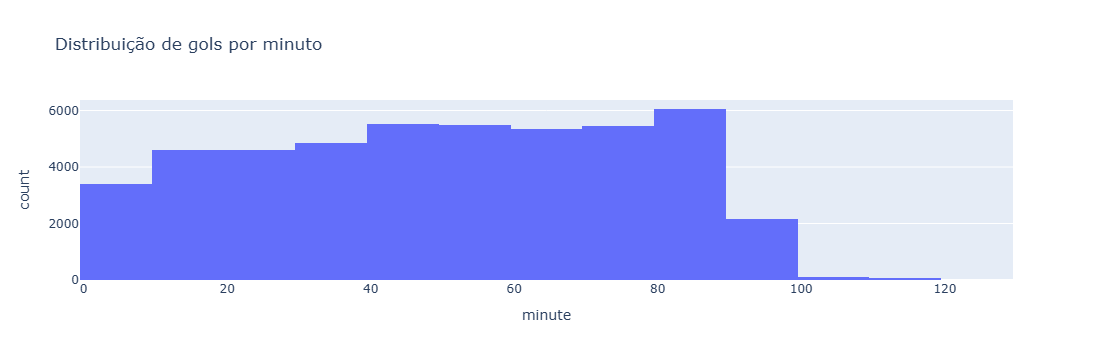

In [25]:
fig = px.histogram(goals.dropna(subset=['minute']), x='minute', nbins=18, 
                   title='Distribuição de gols por minuto')
fig.show()

In [26]:
merged['decada'] = (merged['year'] // 10 * 10)

penal_por_decada = merged.groupby('decada')['penalty'].mean() * 100
print(penal_por_decada)

decada
1910    9.090909
1920    3.789474
1930    3.903904
1940    3.194888
1950    4.678771
1960    4.082442
1970    6.450500
1980    5.888622
1990    6.211180
2000    5.962827
2010    8.034258
2020    9.367851
Name: penalty, dtype: float64


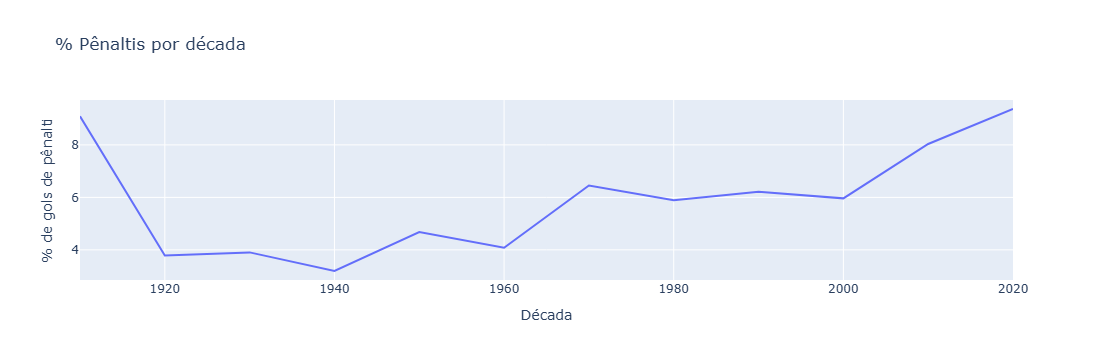

In [27]:
px.line(x=penal_por_decada.index, y=penal_por_decada.values, 
        labels={'x':'Década','y':'% de gols de pênalti'},
        title='% Pênaltis por década').show()

In [28]:
top20 = goals_validos['scorer'].value_counts().head(20)
print(top20)

scorer
Cristiano Ronaldo      124
Harry Kane              75
Lionel Messi            71
Robert Lewandowski      69
Romelu Lukaku           67
Edin Džeko              58
Kylian Mbappé           55
Erling Haaland          53
Aleksandar Mitrović     52
Luis Suárez             51
Ali Daei                49
Miroslav Klose          48
Carlos Ruiz             47
Memphis Depay           44
Robbie Keane            44
Zlatan Ibrahimović      44
David Villa             41
Clint Dempsey           41
Samuel Eto'o            40
Andriy Shevchenko       40
Name: count, dtype: int64


In [29]:
top_copa = goals_validos[goals_validos['tournament'].str.contains('World Cup', na=False)]['scorer'].value_counts().head(20)
print(top_copa)

scorer
Lionel Messi          57
Cristiano Ronaldo     52
Luis Suárez           40
Carlos Ruiz           39
Harry Kane            39
Robert Lewandowski    37
Ali Daei              35
Kylian Mbappé         33
Edin Džeko            32
Miroslav Klose        29
Sardar Azmoun         29
Erling Haaland        28
Son Heung-min         28
Karim Bagheri         28
Andriy Shevchenko     28
Mehdi Taremi          27
Romelu Lukaku         27
Kazuyoshi Miura       27
Memphis Depay         26
Ali Mabkhout          26
Name: count, dtype: int64


In [30]:
# Todos os gols FEITOS pelo Brasil (sem contra)
brasil_gols = merged[(merged['team'] == 'Brazil') & (merged['own_goal'] == False) & (merged['scorer'].notna())].copy()

In [31]:
# Todos os jogos do Brasil
brasil_jogos = results[(results['home_team'] == 'Brazil') | (results['away_team'] == 'Brazil')].copy()

In [35]:
# Cria coluna resultado pro Brasil
def resultado_br(row):
    if row['home_team'] == 'Brazil':
        if row['home_score'] > row['away_score']: return 'Vitória'
        if row['home_score'] < row['away_score']: return 'Derrota'
        return 'Empate'
    else:
        if row['away_score'] > row['home_score']: return 'Vitória'
        if row['away_score'] < row['home_score']: return 'Derrota'
        return 'Empate'

brasil_jogos['resultado_br'] = brasil_jogos.apply(resultado_br, axis=1)

In [36]:
top_br = brasil_gols['scorer'].value_counts().head(15)
print(top_br)

scorer
Ronaldo              39
Neymar               34
Romário              33
Pelé                 26
Ademir de Menezes    22
Rivaldo              21
Luís Fabiano         20
Bebeto               19
Robinho              18
Zico                 18
Zizinho              17
Kaká                 17
Adriano              17
Ronaldinho           17
Jair                 15
Name: count, dtype: int64


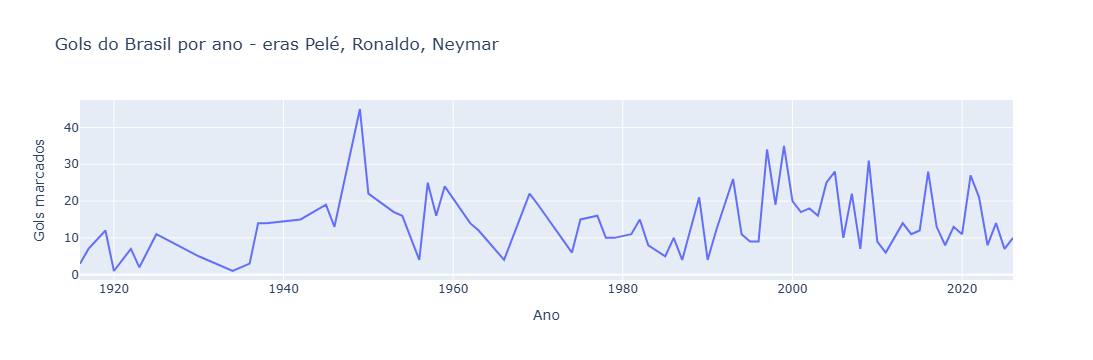

In [40]:
gols_por_ano = brasil_gols.groupby('year').size()

fig = px.line(x=gols_por_ano.index, y=gols_por_ano.values,
              title='Gols do Brasil por ano - eras Pelé, Ronaldo, Neymar')
fig.update_layout(
    xaxis_title="Ano",
    yaxis_title="Gols marcados"
)

fig.show()

In [38]:
# Quem mais sofreu gol do Brasil
vitimas = brasil_gols['away_team'].where(brasil_gols['home_team'] == 'Brazil', brasil_gols['home_team']).value_counts().head(10)
# Na prática, é mais simples:
vitimas = brasil_gols.apply(lambda r: r['away_team'] if r['home_team'] == 'Brazil' else r['home_team'], axis=1).value_counts().head(10)
print("Quem mais levou do Brasil:\n", vitimas)

Quem mais levou do Brasil:
 Chile        105
Paraguay      98
Venezuela     96
Bolivia       95
Peru          79
Ecuador       74
Uruguay       70
Argentina     63
Colombia      59
Mexico        31
Name: count, dtype: int64


In [39]:
# Contra quem o Brasil mais perde?
derrotas = brasil_jogos[brasil_jogos['resultado_br'] == 'Derrota']['home_team'].where(
    brasil_jogos['home_team'] != 'Brazil', brasil_jogos['away_team']).value_counts().head(10)
print("\nQuem mais venceu o Brasil:\n", derrotas)




Quem mais venceu o Brasil:
 home_team
Argentina    41
Uruguay      21
Paraguay     12
Mexico       10
Chile         8
Bolivia       6
France        6
Italy         5
Peru          5
Germany       5
Name: count, dtype: int64
